# Explicación de `Gini`y `Entropy`

**Autor:** Jazna Meza Hidalgo

**Correo Electrónico:** ymeza@ubiobio.cl

**Fecha de Creación:** Octubre de 2026  
**Versión:** 1.0  

---

## Descripción

Este notebook ofrece la explicación de 2 de los criterios de división que usa el árbol de decisión.


---

## Requisitos de Software

Este notebook fue desarrollado con Python 3.12. A continuación se listan las bibliotecas necesarias:

- pandas (>=1.1.0)
- matplotlib (3.7.1)
- numpy (2.0.2)


Para verificar la versión instalada ejecutar usando el siguiente comando, usando la librería de la cual quieres saber la versión:

```python
import pandas as pd
print(pd.__version__)
````

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import math

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
# 1. Cargar un conjunto de datos de prueba
iris = load_iris()
X, y = iris.data, iris.target

In [ ]:
iris.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [ ]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [ ]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

# Análisis de la variable objetivo

In [ ]:
# Muestra la distribución de la variable objetivo (y)
print("--- Distribución de la variable objetivo (y) ---")
print(np.unique(y, return_counts=True))

--- Distribución de la variable objetivo (y) ---
(array([0, 1, 2]), array([50, 50, 50]))


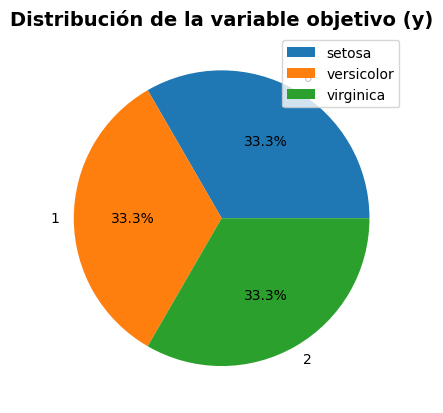

In [ ]:
# Grafica la distribución de la variable objetivo
plt.pie(np.unique(y, return_counts=True)[1], labels=np.unique(y), autopct='%1.1f%%')
plt.legend(iris.target_names)
plt.title("Distribución de la variable objetivo (y)", fontsize=14, fontweight="bold")
plt.show()

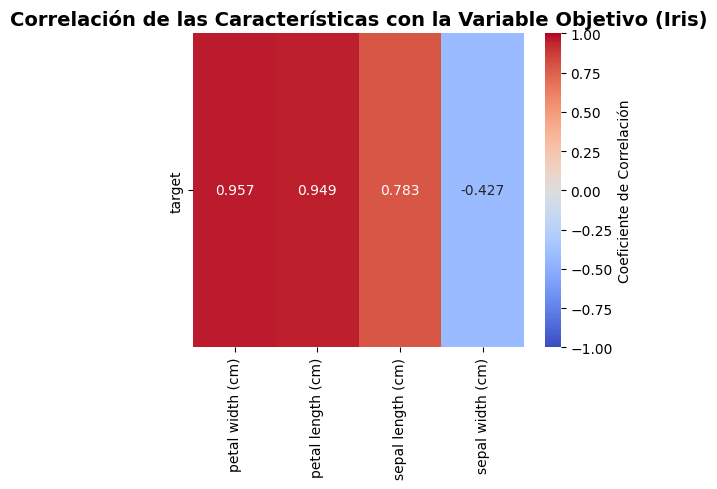

In [ ]:
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="target")  # 0: setosa, 1: versicolor, 2: virginica

# 2. Unir X e y en un DataFrame para calcular la correlación
data_all = pd.concat([X, y], axis=1)

# 3. Calcular la matriz de correlación y aislar la columna 'target'
corr_matrix = data_all.corr()
target_corr = corr_matrix[["target"]].drop("target").sort_values(by="target", ascending=False)

# 4. Graficar el mapa de calor
plt.figure(figsize=(5, 5))
sns.heatmap(
    target_corr.T,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Coeficiente de Correlación"},
)

plt.title("Correlación de las Características con la Variable Objetivo (Iris)",
          fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Creación y entrenamiento de los modelos

In [ ]:
# Dividir en datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=29)

# Instanciar el Árbol de Decisión
# Por defecto usa Gini (criterion='gini')
model_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=29)

# Usando Entropy
model_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=29)

In [ ]:
# Entrenar los modelos
model_gini.fit(X_train, y_train)
model_entropy.fit(X_train, y_train)

# Evaluar la precisión sobre el conjunto de prueba
accuracy = model_gini.score(X_test, y_test)
print(f"Precisión del modelo (Gini): {accuracy * 100:.2f}%")

# Evaluar la precisión sobre el conjunto de prueba
accuracy_e = model_entropy.score(X_test, y_test)
print(f"Precisión del modelo (Entropy): {accuracy_e * 100:.2f}%")

Precisión del modelo (Gini): 90.00%
Precisión del modelo (Entropy): 93.33%


In [ ]:
X_train.shape

(120, 4)

# Visualización de los árboles

--- Reglas del Árbol (Criterio Gini) ---
|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 5.35
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  5.35
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- class: 2



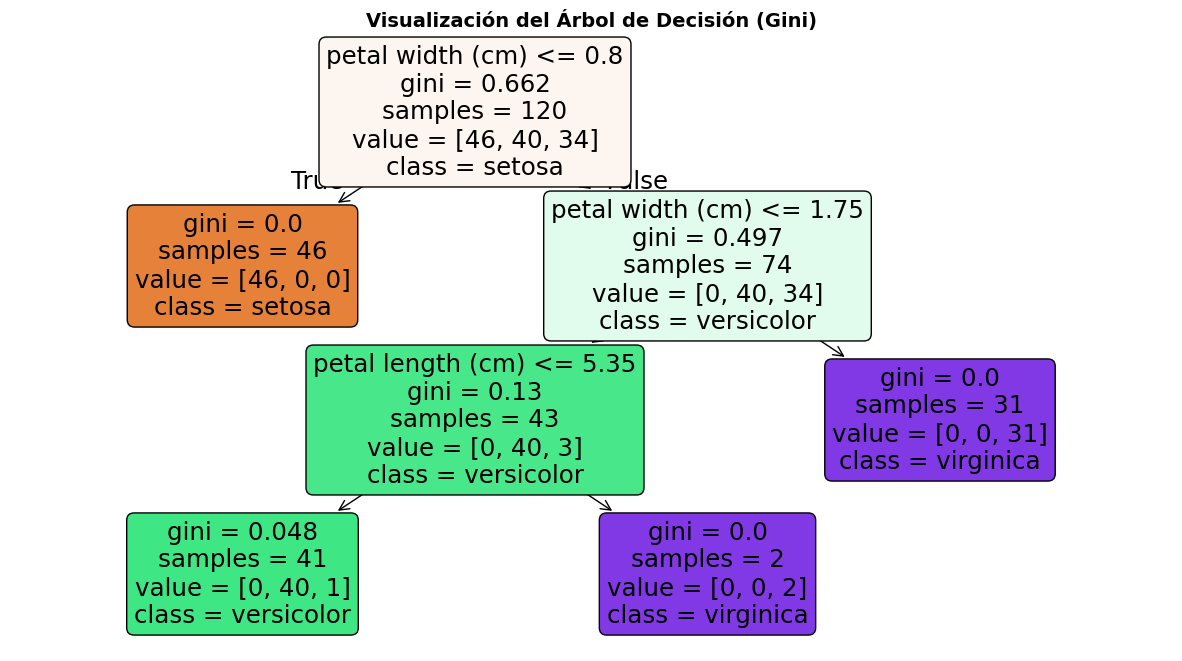

In [ ]:
reglas_texto = export_text(model_gini, feature_names=iris.feature_names)
print("--- Reglas del Árbol (Criterio Gini) ---")
print(reglas_texto)

# Graficar el Árbol de Decisión mostrando los nodos y sus valores
plt.figure(figsize=(15, 8))
plot_tree(
    model_gini,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Visualización del Árbol de Decisión (Gini)", fontsize=14, fontweight="bold")
plt.show()

--- Reglas del Árbol (Criterio Entropy) ---
|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- class: 2



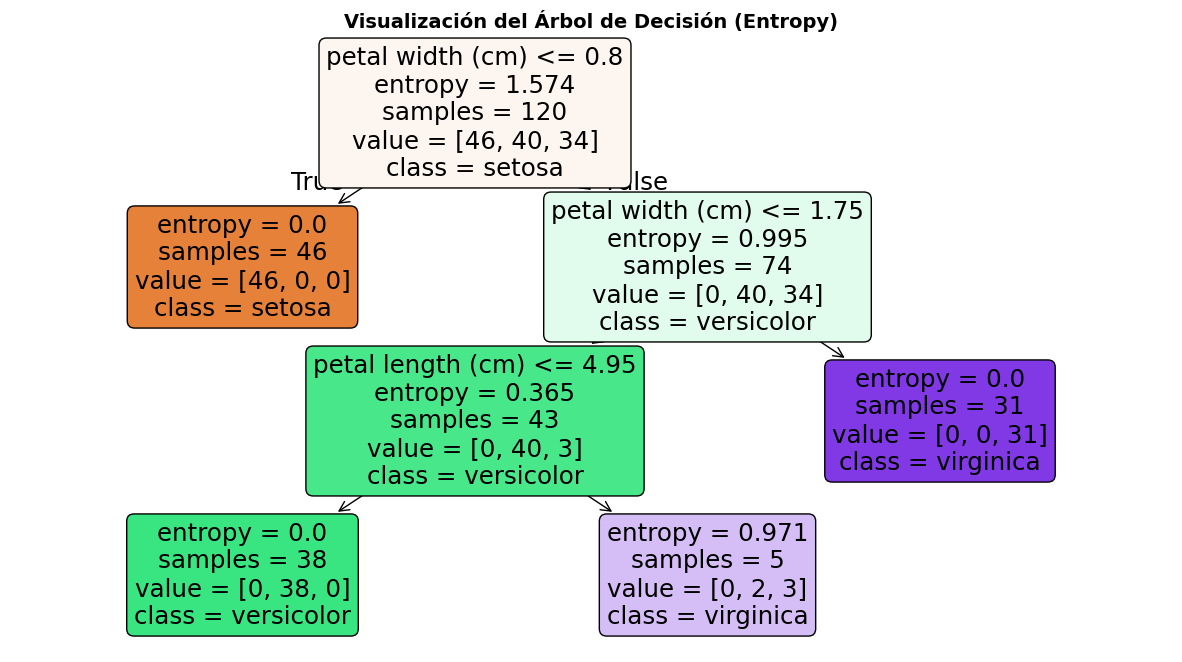

In [ ]:
reglas_texto_e = export_text(model_entropy, feature_names=iris.feature_names)
print("--- Reglas del Árbol (Criterio Entropy) ---")
print(reglas_texto_e)

# Graficar el Árbol de Decisión mostrando los nodos y sus valores
plt.figure(figsize=(15, 8))
plot_tree(
    model_entropy,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)


plt.title("Visualización del Árbol de Decisión (Entropy)", fontsize=14, fontweight="bold")
plt.show()

# Matrices de confusión

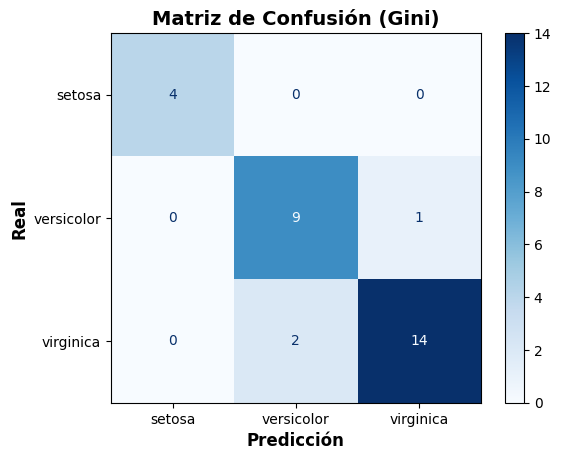

In [ ]:
y_pred_gini = model_gini.predict(X_test)
cm = confusion_matrix(y_test, y_pred_gini)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)

disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Matriz de Confusión (Gini)", fontsize=14, fontweight="bold")
plt.xlabel('Predicción', fontsize=12, fontweight="bold")
plt.ylabel('Real', fontsize=12, fontweight="bold")
plt.show()


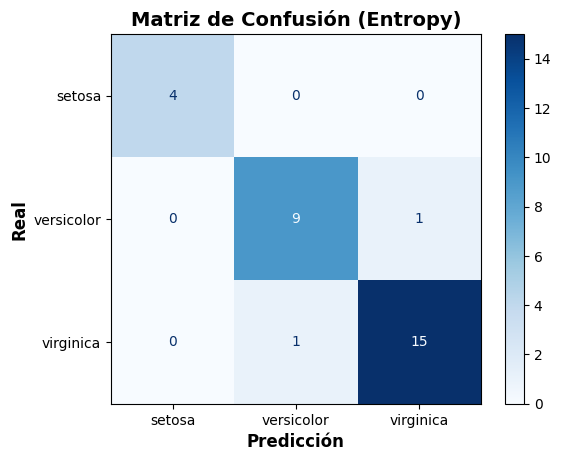

In [ ]:

y_pred_entropy = model_entropy.predict(X_test)
cm = confusion_matrix(y_test, y_pred_entropy)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)

disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Matriz de Confusión (Entropy)", fontsize=14, fontweight="bold")
plt.xlabel('Predicción', fontsize=12, fontweight="bold")
plt.ylabel('Real', fontsize=12, fontweight="bold")
plt.show()

# Bonus - Explicación de criterios: `Entropy` y `Gini`

$Impureza Gini=1 - \sum{(p_i)^2}$

$Entropia=- \sum{p_i*\log_2(p_i)}$

In [ ]:
def calcular_gini(cantidades: np.array):
    total = sum(cantidades)
    if total == 0:
        return 0.0
    # Impureza de Gini = 1 - sum(p_i^2)
    probabilidades = [c / total for c in cantidades]
    return 1.0 - sum(p**2 for p in probabilidades)

def calcular_entropia(cantidades: np.array):
    total = sum(cantidades)
    if total == 0:
        return 0.0
    probabilidades = [c / total for c in cantidades]
    # Entropía = - sum(p_i * log2(p_i))
    return -sum(p * math.log2(p) for p in probabilidades if p > 0)

# Define las cajas de la dispoaitiva: [chocolates, caramelos]
caja_A = [10]  # Pura
caja_B = [5, 5]   # Caótica (máxima mezcla)
caja_C = [9, 1]   # Casi pura

print("--- Impureza de Gini (Rango 0.0 a 0.5) ---")
print(f"Caja A (10 chocolates, 0 caramelos): {calcular_gini(caja_A):.4f}")
print(f"Caja B (5 chocolates, 5 caramelos):  {calcular_gini(caja_B):.4f}")
print(f"Caja C (9 chocolates, 1 caramelo):   {calcular_gini(caja_C):.4f}")

print("\n--- Entropía (Rango 0.0 a 1.0) ---")
print(f"Caja A (10 chocolates, 0 caramelos): {calcular_entropia(caja_A):.4f}")
print(f"Caja B (5 chocolates, 5 caramelos):  {calcular_entropia(caja_B):.4f}")
print(f"Caja C (9 chocolates, 1 caramelo):   {calcular_entropia(caja_C):.4f}")

--- Impureza de Gini (Rango 0.0 a 0.5) ---
Caja A (10 chocolates, 0 caramelos): 0.0000
Caja B (5 chocolates, 5 caramelos):  0.5000
Caja C (9 chocolates, 1 caramelo):   0.1800

--- Entropía (Rango 0.0 a 1.0) ---
Caja A (10 chocolates, 0 caramelos): -0.0000
Caja B (5 chocolates, 5 caramelos):  1.0000
Caja C (9 chocolates, 1 caramelo):   0.4690
